In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)

PyTorch: 2.9.1 | urządzenie: cpu


In [3]:
pil = Image.open("kot.jpg").convert("L").convert("RGB")

w, h = pil.size
m = min(w, h)
left, top = (w - m) // 2, (h - m) // 2
pil = pil.crop((left, top, left + m, top + m)).resize((224, 224))

rgb = torch.from_numpy(np.array(pil)).float().permute(2, 0, 1).unsqueeze(0) / 255.0  # [1,3,H,W]
gray = rgb.mean(1, keepdim=True)                                                     # [1,1,H,W]
print(gray.shape)  # powinno być torch.Size([1, 1, 224, 224])

torch.Size([1, 1, 224, 224])


In [4]:
def out_dim(in_size, k, s=1, p=0, d=1):
    return (in_size + 2*p - d*(k-1) - 1)//s + 1

IN = 32
configs = [
    dict(k=3, s=1, p=1, d=1),
    dict(k=3, s=2, p=1, d=1),
    dict(k=5, s=1, p=2, d=1),
    dict(k=3, s=1, p=2, d=2),
    dict(k=7, s=2, p=3, d=1),
]

print(f"in={IN}")
print(f"{'k':>2} {'s':>2} {'p':>2} {'d':>2} | {'wzór':>5} {'Conv2d':>7}")
x = torch.randn(1, 3, IN, IN)
for c in configs:
    conv = nn.Conv2d(3, 8, kernel_size=c['k'], stride=c['s'], padding=c['p'], dilation=c['d'])
    real = conv(x).shape[-1]
    formula = out_dim(IN, **c)
    ok = '✓' if real == formula else '✗'
    print(f"{c['k']:>2} {c['s']:>2} {c['p']:>2} {c['d']:>2} | {formula:>5} {real:>7}  {ok}")

in=32
 k  s  p  d |  wzór  Conv2d
 3  1  1  1 |    32      32  ✓
 3  2  1  1 |    16      16  ✓
 5  1  2  1 |    32      32  ✓
 3  1  2  2 |    32      32  ✓
 7  2  3  1 |    16      16  ✓


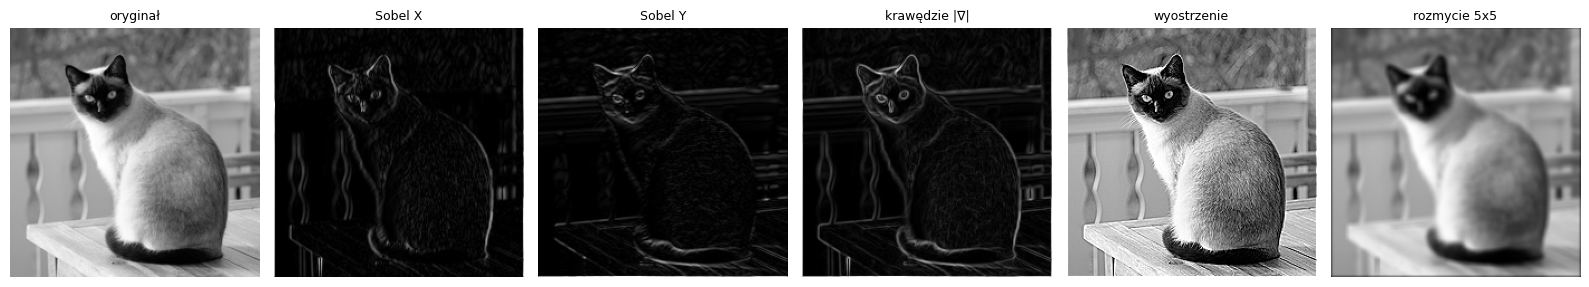

In [5]:
def kernel(t):
    return torch.tensor(t, dtype=torch.float32).view(1, 1, *np.array(t).shape)

sobel_x = kernel([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])
sobel_y = kernel([[-1, -2, -1], [0, 0, 0], [1, 2, 1]])
sharpen = kernel([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
blur    = torch.ones(1, 1, 5, 5) / 25.0

gx = F.conv2d(gray, sobel_x, padding=1)
gy = F.conv2d(gray, sobel_y, padding=1)
edges = (gx**2 + gy**2).sqrt()

results = {
    "oryginał": gray,
    "Sobel X": gx.abs(),
    "Sobel Y": gy.abs(),
    "krawędzie |∇|": edges,
    "wyostrzenie": F.conv2d(gray, sharpen, padding=1).clamp(0, 1),
    "rozmycie 5x5": F.conv2d(gray, blur, padding=2),
}

fig, axes = plt.subplots(1, len(results), figsize=(16, 3))
for ax, (name, out) in zip(axes, results.items()):
    ax.imshow(out[0, 0].detach(), cmap="gray")
    ax.set_title(name, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig("reczne_jadra.png", dpi=150, bbox_inches="tight")
plt.show()

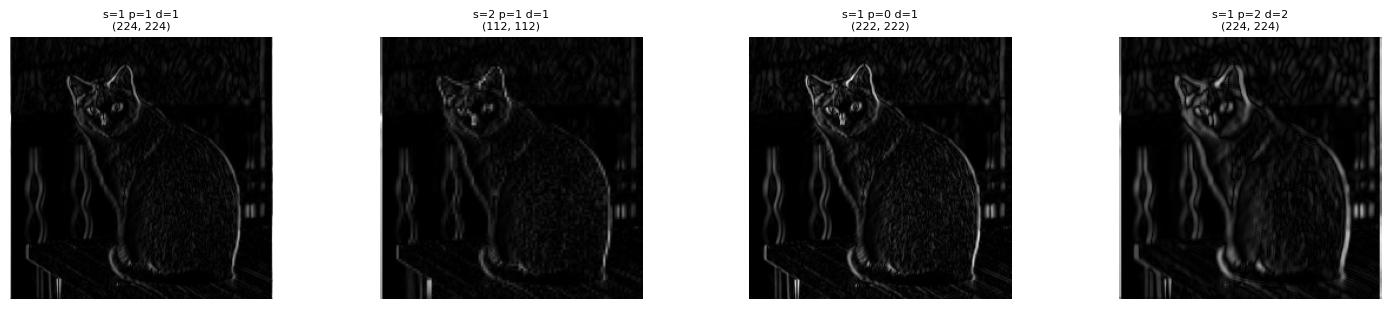

In [6]:
settings = [
    dict(stride=1, padding=1, dilation=1),
    dict(stride=2, padding=1, dilation=1),
    dict(stride=1, padding=0, dilation=1),
    dict(stride=1, padding=2, dilation=2),
]

fig, axes = plt.subplots(1, len(settings), figsize=(15, 3.2))
for ax, s in zip(axes, settings):
    out = F.conv2d(gray, sobel_x, **s)
    ax.imshow(out[0, 0].abs().detach(), cmap="gray")
    ax.set_title(f"s={s['stride']} p={s['padding']} d={s['dilation']}\n{tuple(out.shape[-2:])}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.savefig("stride_padding_dilation.png", dpi=150, bbox_inches="tight")
plt.show()

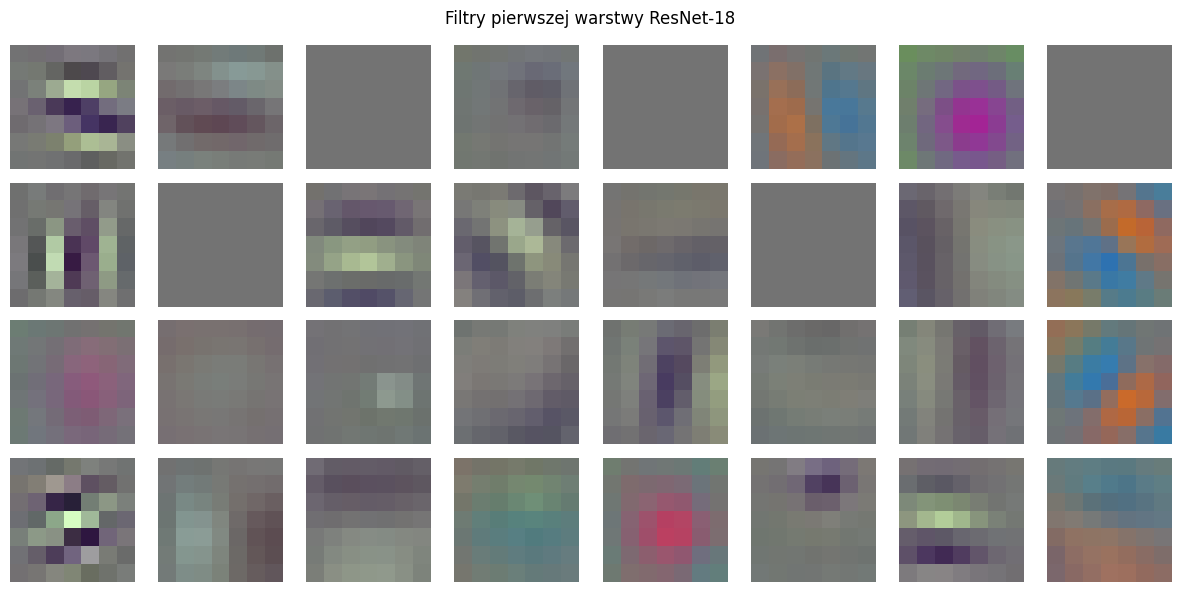

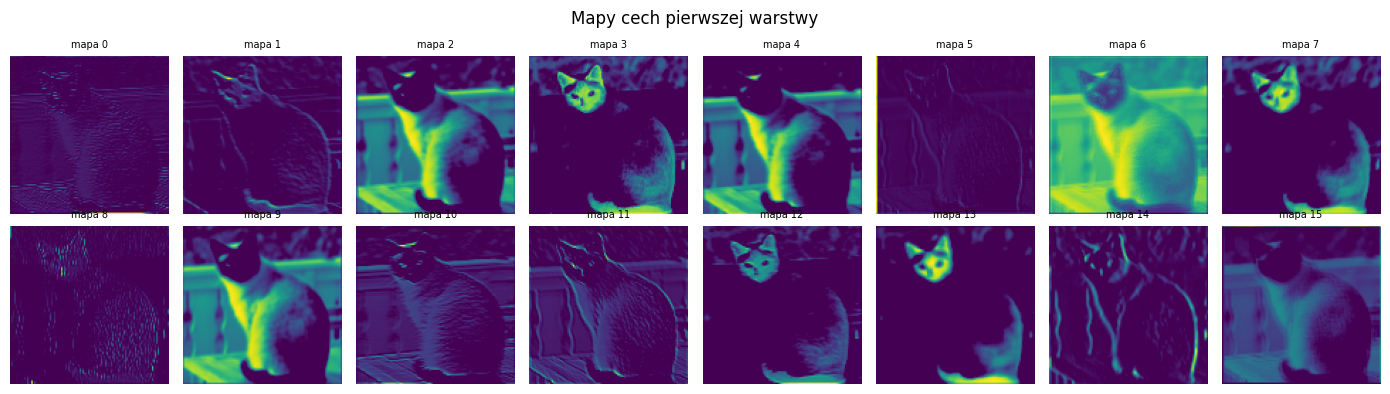

In [7]:
from torchvision.models import resnet18, ResNet18_Weights

weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights).to(device).eval()

W = model.conv1.weight.data.clone().cpu()
Wn = (W - W.min()) / (W.max() - W.min())
fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(Wn[i].permute(1, 2, 0)); ax.axis("off")
fig.suptitle("Filtry pierwszej warstwy ResNet-18")
plt.tight_layout()
plt.savefig("resnet_filtry.png", dpi=150, bbox_inches="tight")
plt.show()

preprocess = weights.transforms()
x = preprocess(pil).unsqueeze(0).to(device)
with torch.no_grad():
    fmaps = torch.relu(model.conv1(x))[0].cpu()

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(fmaps[i], cmap="viridis"); ax.set_title(f"mapa {i}", fontsize=7); ax.axis("off")
fig.suptitle("Mapy cech pierwszej warstwy")
plt.tight_layout()
plt.savefig("resnet_mapy.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
box3 = torch.ones(1, 1, 3, 3) / 9.0
box5 = torch.ones(1, 1, 5, 5) / 25.0

g = torch.tensor([1., 4., 6., 4., 1.])
gauss5 = (g[:, None] * g[None, :] / 256.0).view(1, 1, 5, 5)

print("sumy wag:", box3.sum().item(), box5.sum().item(), gauss5.sum().item())
print(gauss5[0, 0])

sumy wag: 1.0 1.0 1.0
tensor([[0.0039, 0.0156, 0.0234, 0.0156, 0.0039],
        [0.0156, 0.0625, 0.0938, 0.0625, 0.0156],
        [0.0234, 0.0938, 0.1406, 0.0938, 0.0234],
        [0.0156, 0.0625, 0.0938, 0.0625, 0.0156],
        [0.0039, 0.0156, 0.0234, 0.0156, 0.0039]])


In [9]:
b3 = F.conv2d(gray, box3,    padding=1)   # k=3 -> p=1
b5 = F.conv2d(gray, box5,    padding=2)   # k=5 -> p=2
g5 = F.conv2d(gray, gauss5,  padding=2)   # k=5 -> p=2
print(b3.shape, b5.shape, g5.shape)       # wszystkie [1,1,224,224]

torch.Size([1, 1, 224, 224]) torch.Size([1, 1, 224, 224]) torch.Size([1, 1, 224, 224])


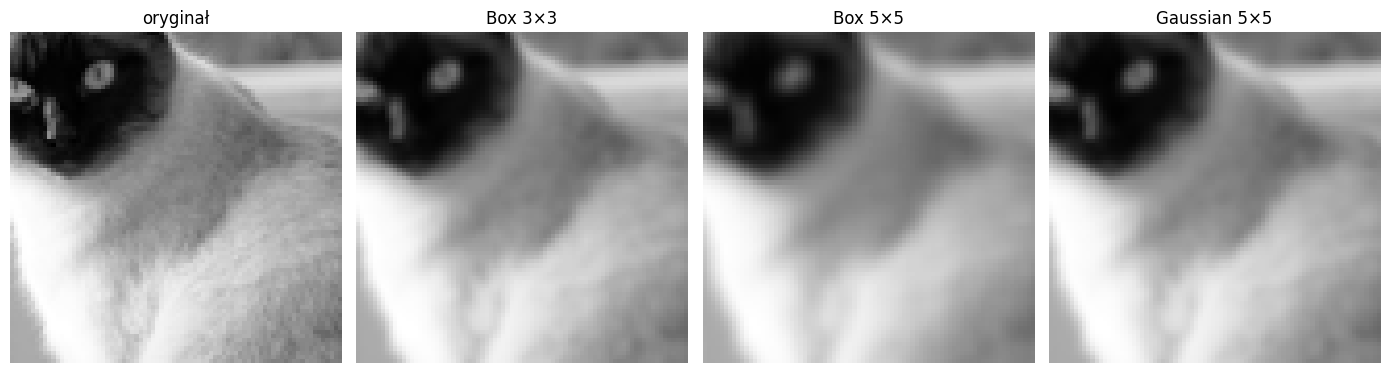

In [11]:
y0, y1 = 50, 130
x0, x1 = 70, 150

crops = {
    "oryginał":     gray[0, 0, y0:y1, x0:x1],
    "Box 3×3":      b3[0, 0, y0:y1, x0:x1],
    "Box 5×5":      b5[0, 0, y0:y1, x0:x1],
    "Gaussian 5×5": g5[0, 0, y0:y1, x0:x1],
}

fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, (name, im) in zip(axes, crops.items()):
    ax.imshow(im.detach(), cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(name); ax.axis("off")
plt.tight_layout()
plt.savefig("box_gauss.png", dpi=150, bbox_inches="tight")
plt.show()